# Customer Behaviour: Exploratory Data Analysis

**Data:** cleaned Online Retail II tables (`sales` and `returns`) from the cleaning notebook.
**Goal:** understand how customers buy, so we can define churn and choose the snapshot dates.

## Setup

In [6]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# One clean style for all charts
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 4)

# Folder where the charts are saved (they will be used in the README)
fig_dir = Path("../reports/figures")
fig_dir.mkdir(parents=True, exist_ok=True)

## Load the cleaned data

In [7]:
# Load the two tables saved by the cleaning notebook
sales = pd.read_parquet("../data/processed/sales.parquet")
returns = pd.read_parquet("../data/processed/returns.parquet")

# Revenue of each row = quantity x price
sales["line_total"] = sales["quantity"] * sales["price"]

print("Sales:", sales.shape)
print("Returns:", returns.shape)
sales.dtypes

Sales: (779425, 10)
Returns: (18390, 9)


invoice                    str
stockcode                  str
description                str
quantity                 int64
invoicedate     datetime64[us]
price                  float64
customer_id              int64
country                    str
source_sheet               str
line_total             float64
dtype: object

## Build an invoice-level table

In [8]:
# One row per invoice. A "purchase" is one invoice (one shopping trip),
# not one product line. A basket with 10 products is still 1 purchase.
invoices = (
    sales.groupby(["customer_id", "invoice"])
    .agg(invoice_date=("invoicedate", "min"), revenue=("line_total", "sum"))
    .reset_index()
)

print("Invoices:", len(invoices), "| Customers:", invoices["customer_id"].nunique())

Invoices: 36969 | Customers: 5878


## When do customers buy? Monthly activity

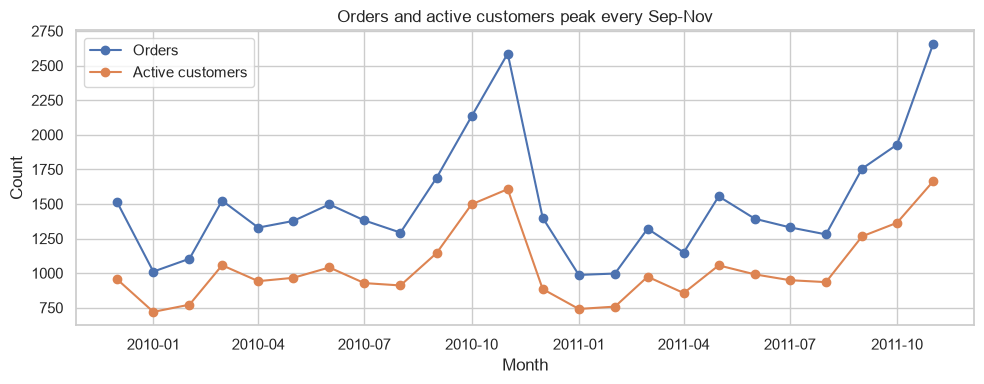

In [9]:
# Orders, active customers and revenue for each month
monthly = invoices.groupby(invoices["invoice_date"].dt.to_period("M")).agg(
    orders=("invoice", "nunique"),
    active_customers=("customer_id", "nunique"),
    revenue=("revenue", "sum"),
)

# Drop the last month: the data ends on 9 Dec 2011, so Dec 2011 is incomplete
monthly_full = monthly.iloc[:-1].copy()
monthly_full.index = monthly_full.index.to_timestamp()

fig, ax = plt.subplots()
ax.plot(monthly_full.index, monthly_full["orders"], marker="o", label="Orders")
ax.plot(monthly_full.index, monthly_full["active_customers"], marker="o", label="Active customers")
ax.set_title("Orders and active customers peak every Sep-Nov")
ax.set_xlabel("Month")
ax.set_ylabel("Count")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "monthly_activity.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** Orders and active customers peak from September to November and fall in January-February, in both years. The test period (Sep-Dec 2011) is therefore a busy season. Dec 2011 is left out because the data ends on 9 Dec.

## How long do customers wait between purchases?

count    31091.0
mean        51.2
std         75.8
min          0.0
50%         24.0
75%         61.0
90%        134.0
95%        206.0
max        714.0
Name: days_since_prev, dtype: float64


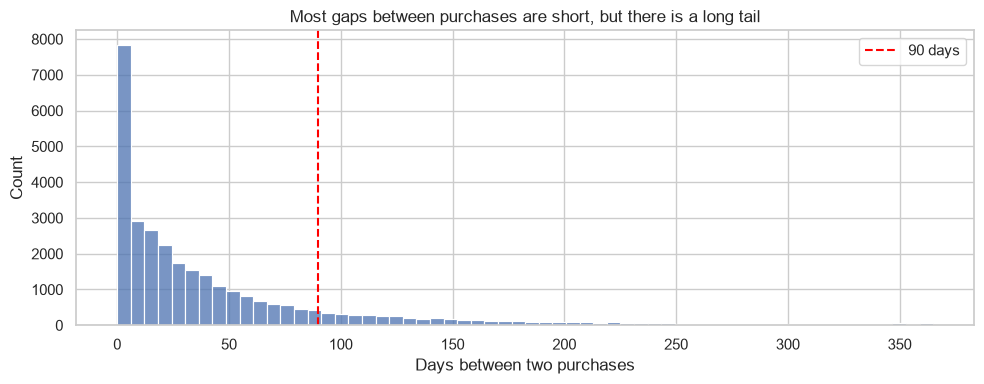

In [11]:
# Days between two consecutive purchases of the same customer
invoices = invoices.sort_values(["customer_id", "invoice_date"])
invoices["days_since_prev"] = invoices.groupby("customer_id")["invoice_date"].diff().dt.days

# Typical gaps: median, 75%, 90% and 95% of the gaps
print(invoices["days_since_prev"].describe(percentiles=[0.5, 0.75, 0.9, 0.95]).round(1))

# Histogram of the gaps, shown up to one year
gaps = invoices["days_since_prev"].dropna()

fig, ax = plt.subplots()
sns.histplot(gaps[gaps <= 365], bins=60, ax=ax)
ax.axvline(90, color="red", linestyle="--", label="90 days")
ax.set_title("Most gaps between purchases are short, but there is a long tail")
ax.set_xlabel("Days between two purchases")
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "purchase_gaps.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** The median gap is 24 days, 75% of gaps are under 61 days and 90% under 134 days. The mean (51 days) is higher than the median because of a long tail of late returns. These gaps only include customers who did come back, so the next section checks the 90-day window in a fairer way.

## Does a 90-day churn window make sense?

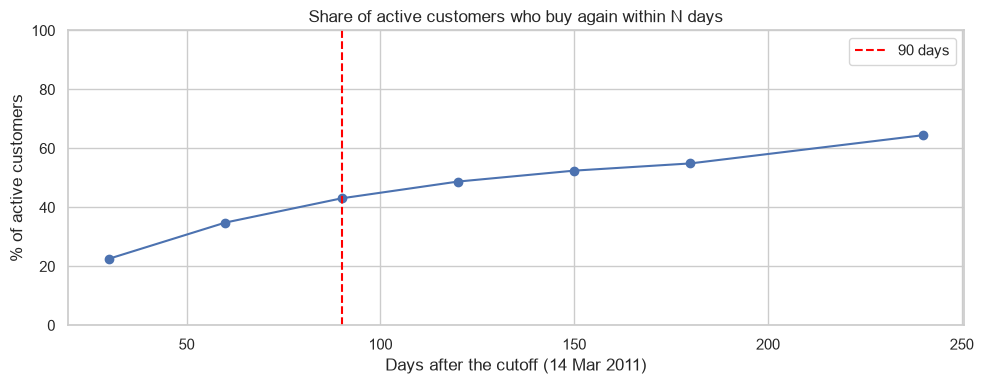

Active customers at the cutoff: 3344


30     0.226
60     0.348
90     0.431
120    0.487
150    0.525
180    0.549
240    0.645
dtype: float64

In [12]:
# Use a TRAINING-period cutoff, so we do not use the valid/test periods to make design decisions
cutoff = pd.Timestamp("2011-03-14")

# Customers with at least one purchase in the 180 days before the cutoff
past = invoices[invoices["invoice_date"] < cutoff]
active = past[past["invoice_date"] >= cutoff - pd.Timedelta(days=180)]["customer_id"].unique()

# For these customers: when did they make their NEXT purchase after the cutoff?
future = invoices[(invoices["invoice_date"] >= cutoff) & (invoices["customer_id"].isin(active))]
days_to_next = (future.groupby("customer_id")["invoice_date"].min() - cutoff).dt.days

# Share of ALL active customers who came back within N days
windows = [30, 60, 90, 120, 150, 180, 240]
back_rate = pd.Series({d: (days_to_next <= d).sum() / len(active) for d in windows})

fig, ax = plt.subplots()
back_rate.mul(100).plot(ax=ax, marker="o")
ax.axvline(90, color="red", linestyle="--", label="90 days")
ax.set_title("Share of active customers who buy again within N days")
ax.set_xlabel("Days after the cutoff (14 Mar 2011)")
ax.set_ylabel("% of active customers")
ax.set_ylim(0, 100)   # full 0-100 scale so the curve is not exaggerated
ax.legend()
plt.tight_layout()
plt.savefig(fig_dir / "repurchase_curve.png", dpi=150, bbox_inches="tight")
plt.show()

print("Active customers at the cutoff:", len(active))
back_rate.round(3)

**Takeaway:** TODO (fill in after running). If the curve flattens after about 90 days, 90 days is a sensible churn window: customers who have not returned by then rarely do. If it keeps rising steeply, the window should be longer.

## How many orders does a typical customer make?

Share of one-time buyers: 27.6 %
count    5878.0
mean        6.3
std        13.0
min         1.0
25%         1.0
50%         3.0
75%         7.0
max       398.0
dtype: float64


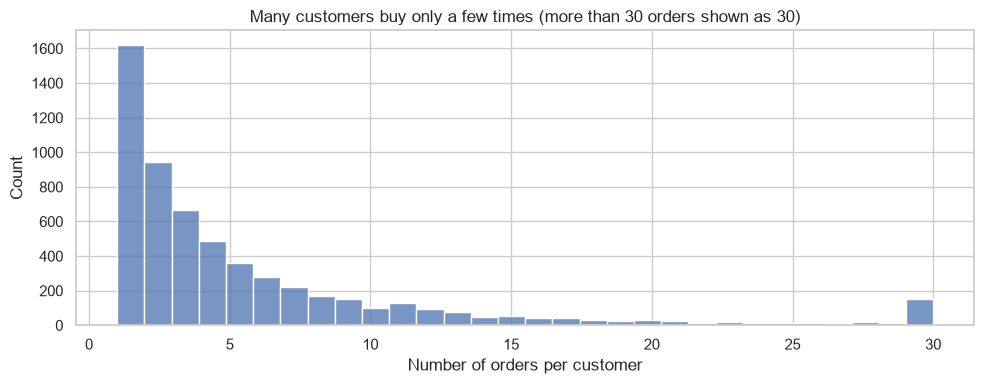

In [13]:
orders_per_customer = invoices.groupby("customer_id").size()

print("Share of one-time buyers:", round((orders_per_customer == 1).mean() * 100, 1), "%")
print(orders_per_customer.describe().round(1))

fig, ax = plt.subplots()
sns.histplot(orders_per_customer.clip(upper=30), bins=30, ax=ax)
ax.set_title("Many customers buy only a few times (more than 30 orders shown as 30)")
ax.set_xlabel("Number of orders per customer")
plt.tight_layout()
plt.savefig(fig_dir / "orders_per_customer.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** 27.6% of customers bought only once and the typical customer has 3 orders. A few customers have hundreds of orders (maximum 398), possibly wholesale customers. These very active customers can distort features later, so we will reduce their effect with log transforms.

## Who brings the money?

Top 10% of customers bring 64% of revenue


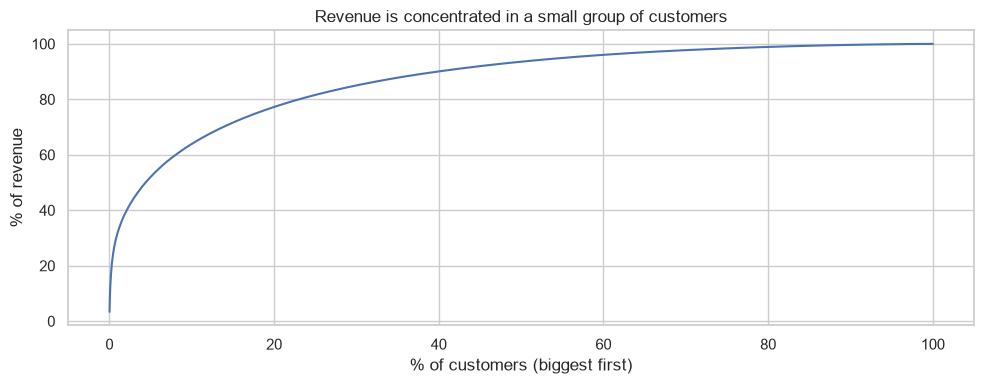

In [14]:
# Total revenue per customer, biggest first
customer_revenue = invoices.groupby("customer_id")["revenue"].sum().sort_values(ascending=False)

# Cumulative share of revenue vs share of customers (Pareto curve)
cum_share = customer_revenue.cumsum() / customer_revenue.sum()
customer_pct = np.arange(1, len(cum_share) + 1) / len(cum_share) * 100

top10 = customer_revenue.head(int(len(customer_revenue) * 0.1)).sum() / customer_revenue.sum()
print(f"Top 10% of customers bring {top10:.0%} of revenue")

fig, ax = plt.subplots()
ax.plot(customer_pct, cum_share * 100)
ax.set_title("Revenue is concentrated in a small group of customers")
ax.set_xlabel("% of customers (biggest first)")
ax.set_ylabel("% of revenue")
plt.tight_layout()
plt.savefig(fig_dir / "revenue_concentration.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** TODO (fill in after running). Write what share of revenue the top 10% of customers bring, and what this means for the campaign: losing a big customer costs far more than losing a small one, so the business decision (Step 7) must use customer value, not only churn probability.

## How big are the orders?

count     36969.0
mean        470.0
std        1359.7
min           0.4
50%         303.0
90%         832.6
99%        3610.5
max      168469.6
Name: revenue, dtype: float64


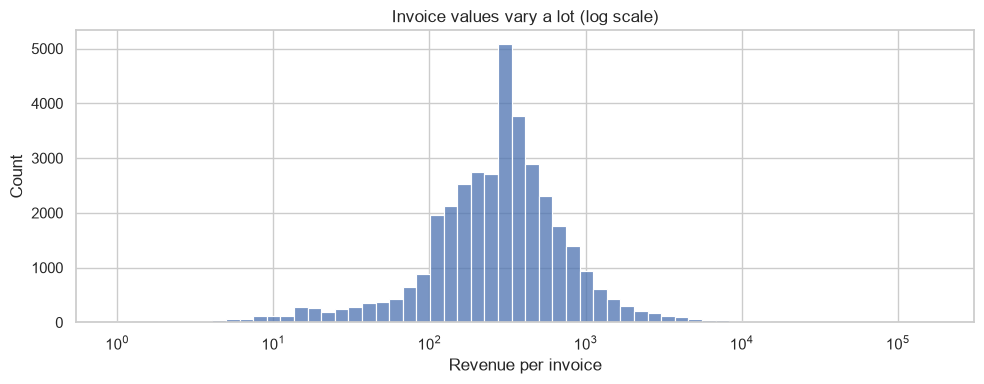

In [15]:
# Spread of invoice values
print(invoices["revenue"].describe(percentiles=[0.5, 0.9, 0.99]).round(1))

fig, ax = plt.subplots()
sns.histplot(invoices["revenue"].clip(lower=1), log_scale=True, bins=60, ax=ax)
ax.set_title("Invoice values vary a lot (log scale)")
ax.set_xlabel("Revenue per invoice")
plt.tight_layout()
plt.savefig(fig_dir / "invoice_value.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** TODO (fill in after running). Compare the median invoice with the 99th percentile. A big gap means outliers, so features such as average basket value will use the median or a log transform.

## Which countries do customers come from?

country
United Kingdom    82.8
EIRE               3.5
Netherlands        3.2
Germany            2.4
France             2.0
Australia          1.0
Spain              0.6
Switzerland        0.6
Name: line_total, dtype: float64


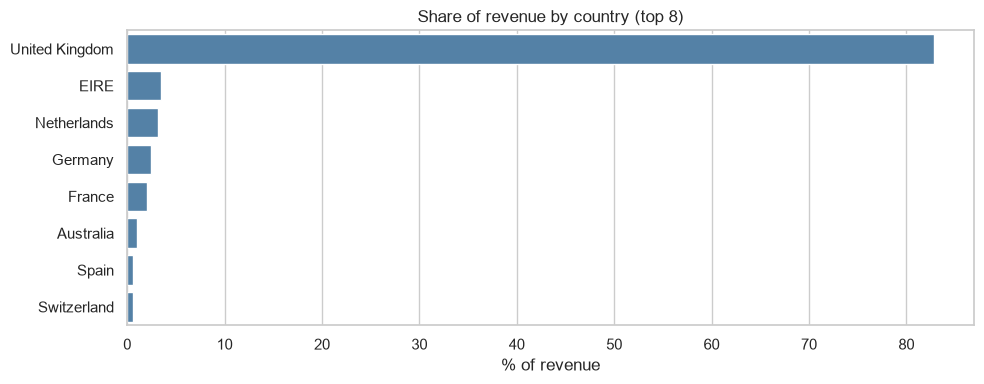

In [16]:
# Share of revenue by country
country_revenue = sales.groupby("country")["line_total"].sum().sort_values(ascending=False)
country_share = (country_revenue / country_revenue.sum() * 100).round(1)

top_countries = country_share.head(8)
print(top_countries)

fig, ax = plt.subplots()
sns.barplot(x=top_countries.values, y=top_countries.index, ax=ax, color="steelblue")
ax.set_title("Share of revenue by country (top 8)")
ax.set_xlabel("% of revenue")
ax.set_ylabel("")
plt.tight_layout()
plt.savefig(fig_dir / "country_share.png", dpi=150, bbox_inches="tight")
plt.show()

**Takeaway:** TODO (fill in after running). If the United Kingdom dominates, we will use a simple `is_uk` feature instead of one column for every country.

## How important are returns?

In [17]:
# Return value (quantity is negative in returns, so take the absolute value)
returns["return_value"] = (returns["quantity"] * returns["price"]).abs()

share = returns["return_value"].sum() / sales["line_total"].sum() * 100
print("Returns value as % of sales value:", round(share, 1))

# Customers with at least one return, among customers who have real purchases
returners = returns[returns["customer_id"].isin(invoices["customer_id"])]["customer_id"].nunique()
print("Customers with at least one return:", returners, f"({returners / invoices['customer_id'].nunique():.0%})")

Returns value as % of sales value: 6.2
Customers with at least one return: 2511 (43%)


**Takeaway:** TODO (fill in after running). Write how big returns are compared with sales and how many customers return items. This is why a "return rate" feature is worth building.

## Findings

- Strong seasonality: orders peak in Sep-Nov and drop in Jan-Feb. Dec 2011 is partial, so it is excluded from the charts.
- Median gap between purchases is 24 days; 75% of gaps are under 61 days and 90% under 134 days.
- 27.6% of customers bought only once; the typical customer has 3 orders.
- Repurchase curve: [x]% of active customers buy again within 90 days and [y]% within 180 days.
- Top 10% of customers bring [z]% of revenue.
- United Kingdom brings [u]% of revenue.
- Returns are [r]% of sales value; [c]% of customers made at least one return.
- Decision: churn = no purchase in the next 90 days, scored only for customers active in the last 180 days.